# Soybean Price Prediction — Rajkot

**Market:** Rajkot district (Gondal mandi, Gujarat)  |  **Target:** daily modal price (₹/quintal)  |  **Models:** Linear Regression, Random Forest, XGBoost

Pipeline: data collection → integration → cleaning → EDA → feature engineering → feature selection → chronological split → scaling → modelling → evaluation (MAE, RMSE, R²) → comparison → feature importance → final model.

> Put the five data files in the same folder as this notebook (or edit `PATHS` below).

## 1. Data Collection

In [1]:
import warnings, joblib
warnings.filterwarnings('ignore')
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_regression
from xgboost import XGBRegressor

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 140)
RANDOM_STATE = 42
TARGET_MARKET, OTHER_MARKET = 'rajkot', 'indore'
TARGET = f'price_{TARGET_MARKET}'

PATHS = dict(
    indore_price  = 'price_indore_market_cleaned_ffill_no_holidays_covid.csv',
    indore_arr    = '1792863217441_arrivals_indore_market_cleaned_ffill_no_holidays_covid.csv',
    rajkot_price  = 'price_data_cleaned_rajkot.xlsx',
    rajkot_arr    = '1792863193832_merged_quantity_2011_2025_filled.csv',
    crude         = 'crude_oil_filled_ffill.csv',
)

In [2]:
indore_price = pd.read_csv(PATHS['indore_price'], parse_dates=['date'])
indore_arr   = pd.read_csv(PATHS['indore_arr'],   parse_dates=['date'])
rajkot_price = pd.read_excel(PATHS['rajkot_price'], sheet_name='Sheet1', parse_dates=['Date']).rename(columns={'Date': 'date'})
rajkot_arr   = pd.read_csv(PATHS['rajkot_arr'],   parse_dates=['Date']).rename(columns={'Date': 'date'})
crude        = pd.read_csv(PATHS['crude'],        parse_dates=['date'])

for name, d in [('Indore price', indore_price), ('Indore arrivals', indore_arr), ('Rajkot price', rajkot_price),
                ('Rajkot arrivals (Gondal)', rajkot_arr), ('Crude oil', crude)]:
    print(f"{name:26s} rows={len(d):5d}  {d['date'].min().date()} -> {d['date'].max().date()}")

Indore price               rows= 4386  2011-01-01 -> 2025-12-31
Indore arrivals            rows= 4386  2011-01-01 -> 2025-12-31
Rajkot price               rows= 4354  2011-01-03 -> 2025-12-31
Rajkot arrivals (Gondal)   rows= 4354  2011-01-03 -> 2025-12-31
Crude oil                  rows= 5771  2011-01-03 -> 2026-10-21


## 2. Data Integration
Each source is reduced to `date` + one value column, then all five are outer-merged on `date`.

In [3]:
sources = {
    'price_indore': indore_price[['date', 'p_modal']].rename(columns={'p_modal': 'price_indore'}),
    'arr_indore':   indore_arr[['date', 'quantity_tonnes']].rename(columns={'quantity_tonnes': 'arr_indore'}),
    'price_rajkot': rajkot_price[['date', 'p_modal']].rename(columns={'p_modal': 'price_rajkot'}),
    'arr_rajkot':   rajkot_arr[['date', 'qty']].rename(columns={'qty': 'arr_rajkot'}),
    'crude':        crude[['date', 'price']].rename(columns={'price': 'crude'}),
}
# duplicate dates inside any source -> average (reported)
for k, d in sources.items():
    n_dup = d['date'].duplicated().sum()
    print(f'{k:13s} duplicate dates: {n_dup}')
    sources[k] = d.groupby('date', as_index=False).mean()

merged = reduce(lambda a, b: a.merge(b, on='date', how='outer'), sources.values()).sort_values('date').reset_index(drop=True)
print('\nmerged shape:', merged.shape)
merged.head()

price_indore  duplicate dates: 0
arr_indore    duplicate dates: 0
price_rajkot  duplicate dates: 0
arr_rajkot    duplicate dates: 0
crude         duplicate dates: 0

merged shape: (5772, 6)


,date,price_indore,arr_indore,price_rajkot,arr_rajkot,crude
0,2011-01-01,2255.0,38.0,NaN,NaN,NaN
1,2011-01-03,2250.0,668.3,2250.0,5.8,91.55
2,2011-01-04,2250.0,668.3,2325.0,4.7,89.38
3,2011-01-05,2100.0,941.1,2315.0,10.9,90.30
4,2011-01-06,2150.0,710.5,2235.0,4.5,88.38


## 3. Data Cleaning
Rules:
1. Keep the common period where price data exists (2011-01-03 → 2025-12-31; crude extends beyond it).
2. The modelling calendar is **Rajkot's own trading days** (rows with a Rajkot price). Non-trading days of the other market are forward-filled (max 5 days).
3. Remaining gaps in arrivals / crude are forward-filled (max 5 days); anything still missing is dropped.
4. Non-positive prices/arrivals are removed. Outliers are flagged but **kept** (price spikes are real market events).

In [4]:
df = merged[(merged['date'] >= '2011-01-03') & (merged['date'] <= '2025-12-31')].copy()
print('Missing values before cleaning:'); print(df.isna().sum().to_string())

df = df[df[TARGET].notna()].copy()                       # Rajkot trading days
df = df.set_index('date').sort_index()
df = df.ffill(limit=5)
df = df.dropna()

# sanity: non-positive values
bad = (df[['price_indore','price_rajkot','arr_indore','arr_rajkot','crude']] <= 0).any(axis=1)
print('\nNon-positive rows removed:', int(bad.sum()))
df = df[~bad]

# outlier flag (IQR x3) - informational
for c in df.columns:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 3*iqr) | (df[c] > q3 + 3*iqr)).sum())
    print(f'{c:13s} extreme outliers (3xIQR): {n_out}')

print('\nMissing after cleaning:', int(df.isna().sum().sum()), '| final shape:', df.shape)
print('Duplicate dates:', int(df.index.duplicated().sum()))
df.describe().round(1)

Missing values before cleaning:
date               0
price_indore    1092
arr_indore      1092
price_rajkot    1123
arr_rajkot      1123
crude              0

Non-positive rows removed: 0
price_indore  extreme outliers (3xIQR): 64
arr_indore    extreme outliers (3xIQR): 66
price_rajkot  extreme outliers (3xIQR): 11
arr_rajkot    extreme outliers (3xIQR): 316
crude         extreme outliers (3xIQR): 0

Missing after cleaning: 0 | final shape: (4272, 5)
Duplicate dates: 0


,price_indore,arr_indore,price_rajkot,arr_rajkot,crude
count,4272.0,4272.0,4272.0,4272.0,4272.0
mean,3880.2,504.2,3720.9,31.0,71.4
std,1186.1,472.9,1134.9,94.0,20.8
min,1120.0,0.0,1580.0,0.0,20.8
25%,3200.0,237.5,3005.0,0.5,53.8
50%,3650.0,378.1,3500.0,3.0,70.0
75%,4300.0,625.7,4255.0,22.0,89.8
max,10250.0,6252.0,8555.0,1403.3,119.8


## 4. Exploratory Data Analysis

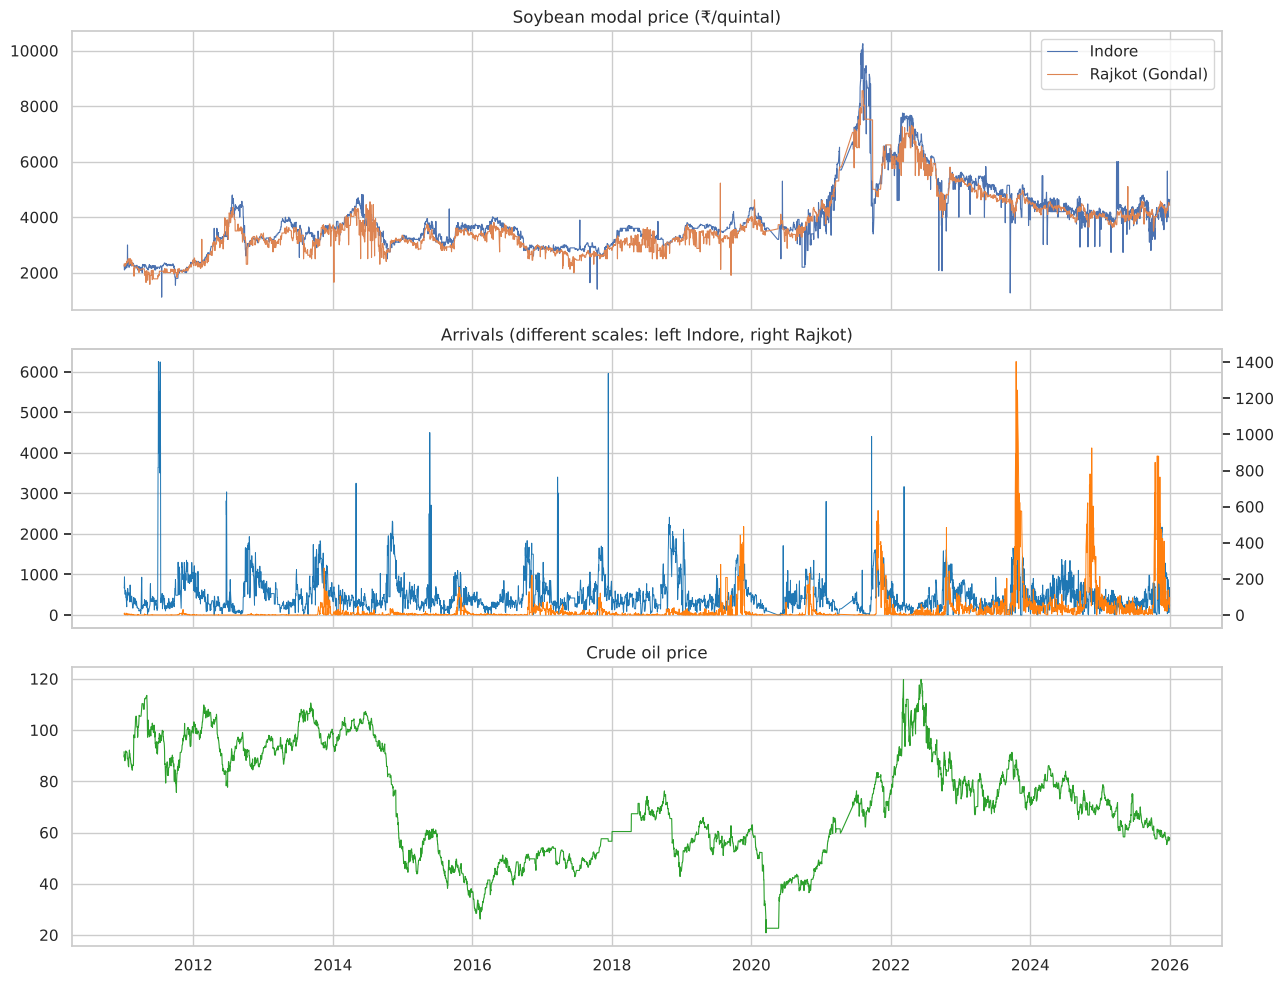

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
axes[0].plot(df.index, df['price_indore'], lw=.8, label='Indore'); axes[0].plot(df.index, df['price_rajkot'], lw=.8, label='Rajkot (Gondal)')
axes[0].set_title('Soybean modal price (₹/quintal)'); axes[0].legend()
axes[1].plot(df.index, df['arr_indore'], lw=.7, color='tab:blue', label='Indore (tonnes)')
ax2 = axes[1].twinx(); ax2.plot(df.index, df['arr_rajkot'], lw=.7, color='tab:orange', label='Rajkot/Gondal (units as supplied)'); ax2.grid(False)
axes[1].set_title('Arrivals (different scales: left Indore, right Rajkot)')
axes[2].plot(df.index, df['crude'], lw=.8, color='tab:green'); axes[2].set_title('Crude oil price')
plt.tight_layout(); plt.show()

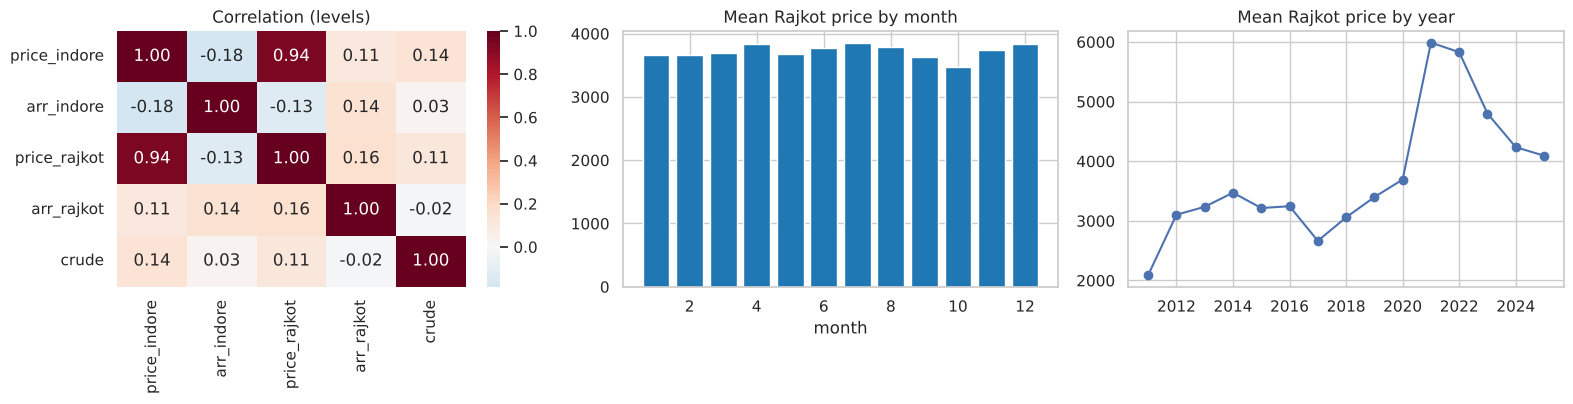

Share of days with Indore-Rajkot price correlation: 0.943


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[0]); axes[0].set_title('Correlation (levels)')
m = df[TARGET].groupby(df.index.month).mean()
axes[1].bar(m.index, m.values, color='tab:blue'); axes[1].set_title('Mean Rajkot price by month'); axes[1].set_xlabel('month')
y = df[TARGET].groupby(df.index.year).mean()
axes[2].plot(y.index, y.values, marker='o'); axes[2].set_title('Mean Rajkot price by year')
plt.tight_layout(); plt.show()

print('Share of days with Indore-Rajkot price correlation:', round(df['price_indore'].corr(df['price_rajkot']), 3))

## 5. Feature Engineering
All features use information available **before** day *t* (lags and rolling windows are shifted), so nothing from the target day leaks into the inputs.

| Group | Features |
|---|---|
| Rajkot price history | lags 1, 2, 3, 7, 14, 30; rolling mean 7 / 30; rolling std 7 |
| Rajkot arrivals | lags 1, 7; rolling mean 7 / 30 |
| Crude oil | lags 1, 7, 30; rolling mean 30 |
| Indore price (cross-market) | lags 1, 7 |
| Calendar | month, day of week |

In [7]:
own_arr, oth_price = f'arr_{TARGET_MARKET}', f'price_{OTHER_MARKET}'
feat = pd.DataFrame(index=df.index)
feat[TARGET] = df[TARGET]

for l in [1, 2, 3, 7, 14, 30]:
    feat[f'price_lag{l}'] = df[TARGET].shift(l)
feat['price_roll7']  = df[TARGET].shift(1).rolling(7).mean()
feat['price_roll30'] = df[TARGET].shift(1).rolling(30).mean()
feat['price_std7']   = df[TARGET].shift(1).rolling(7).std()

for l in [1, 7]:
    feat[f'arr_lag{l}'] = df[own_arr].shift(l)
feat['arr_roll7']  = df[own_arr].shift(1).rolling(7).mean()
feat['arr_roll30'] = df[own_arr].shift(1).rolling(30).mean()

for l in [1, 7, 30]:
    feat[f'crude_lag{l}'] = df['crude'].shift(l)
feat['crude_roll30'] = df['crude'].shift(1).rolling(30).mean()

for l in [1, 7]:
    feat[f'{OTHER_MARKET}_price_lag{l}'] = df[oth_price].shift(l)

feat['month'] = feat.index.month
feat['dayofweek'] = feat.index.dayofweek

feat = feat.dropna()
FEATURES = [c for c in feat.columns if c != TARGET]
print('rows:', len(feat), '| candidate features:', len(FEATURES))
feat.head()

rows: 4242 | candidate features: 21


,price_rajkot,price_lag1,price_lag2,price_lag3,price_lag7,price_lag14,price_lag30,price_roll7,price_roll30,price_std7,...,arr_roll7,arr_roll30,crude_lag1,crude_lag7,crude_lag30,crude_roll30,indore_price_lag1,indore_price_lag7,month,dayofweek
date,,,,,,,,,,,,,,,,,,,,,
2011-02-09,2425.0,2455.0,2330.0,2480.0,2415.0,2435.0,2250.0,2447.857143,2376.000000,60.198086,...,2.771429,3.805000,86.94,90.77,91.55,89.537667,2300.0,2325.0,2,2
2011-02-10,2445.0,2425.0,2455.0,2330.0,2460.0,2475.0,2325.0,2449.285714,2381.833333,59.401780,...,2.771429,3.818333,86.71,90.86,89.38,89.376333,2300.0,2325.0,2,3
2011-02-11,2455.0,2445.0,2425.0,2455.0,2515.0,2505.0,2315.0,2447.142857,2385.833333,59.221135,...,2.271429,3.695000,86.73,90.54,90.30,89.288000,2251.0,2300.0,2,4
2011-02-12,2455.0,2455.0,2445.0,2425.0,2480.0,2470.0,2235.0,2438.571429,2390.500000,51.616719,...,2.014286,3.365000,85.58,89.03,88.38,89.130667,2300.0,2275.0,2,5
2011-02-14,2250.0,2455.0,2455.0,2445.0,2480.0,2405.0,2250.0,2435.000000,2397.833333,49.074773,...,1.985714,3.271667,85.58,89.03,88.03,89.037333,2250.0,2300.0,2,0


## 6. Feature Selection
The chronological split point is fixed here (first 80 % of days = training) so that selection statistics are computed on **training data only**.
Features are ranked by |correlation| and mutual information with the target; features with negligible signal (|r| < 0.05 on train) are dropped.

In [8]:
n_train = int(len(feat) * 0.80)
train_part = feat.iloc[:n_train]

corr = train_part[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET)
mi = pd.Series(mutual_info_regression(train_part[FEATURES], train_part[TARGET], random_state=RANDOM_STATE), index=FEATURES)
sel = pd.DataFrame({'abs_corr': corr.abs(), 'mutual_info': mi}).sort_values('abs_corr', ascending=False)
print(sel.round(3).to_string())

SELECTED = sel.index[sel['abs_corr'] >= 0.05].tolist()
print('\nDropped:', [f for f in FEATURES if f not in SELECTED])
print('Selected', len(SELECTED), 'features')

                   abs_corr  mutual_info
price_lag1            0.984        2.409
price_roll7           0.984        1.873
price_lag2            0.978        1.941
price_lag3            0.975        1.770
price_lag7            0.967        1.658
price_roll30          0.965        1.762
indore_price_lag1     0.950        1.475
price_lag14           0.950        1.477
indore_price_lag7     0.948        1.405
price_lag30           0.910        1.272
price_std7            0.285        0.336
arr_roll30            0.255        0.952
arr_roll7             0.176        0.547
arr_lag7              0.162        0.324
arr_lag1              0.147        0.429
crude_lag1            0.112        1.039
crude_lag7            0.106        0.930
crude_roll30          0.098        1.254
crude_lag30           0.083        0.944
dayofweek             0.008        0.000
month                 0.005        0.628

Dropped: ['month', 'dayofweek']
Selected 19 features


## 7. Train-Test Split (chronological)

In [9]:
X, y = feat[SELECTED], feat[TARGET]
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]
print(f'Train: {len(X_train)} rows  {X_train.index.min().date()} -> {X_train.index.max().date()}')
print(f'Test : {len(X_test)} rows  {X_test.index.min().date()} -> {X_test.index.max().date()}')
print(f'Train price range: {y_train.min():.0f} - {y_train.max():.0f} | Test price range: {y_test.min():.0f} - {y_test.max():.0f}')

Train: 3393 rows  2011-02-09 -> 2023-01-31
Test : 849 rows  2023-02-01 -> 2025-12-31
Train price range: 1580 - 8555 | Test price range: 3500 - 5230


## 8. Feature Scaling
`StandardScaler` is fitted on the training set only and used for Linear Regression. Tree models (Random Forest, XGBoost) are scale-invariant and use raw features.

In [10]:
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=SELECTED)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  index=X_test.index,  columns=SELECTED)
X_train_s.describe().loc[['mean', 'std']].round(2)

,price_lag1,price_roll7,price_lag2,price_lag3,price_lag7,price_roll30,indore_price_lag1,price_lag14,indore_price_lag7,price_lag30,price_std7,arr_roll30,arr_roll7,arr_lag7,arr_lag1,crude_lag1,crude_lag7,crude_roll30,crude_lag30
mean,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 9–10. Model Building & Training
Random Forest and XGBoost are tuned with `RandomizedSearchCV` using `TimeSeriesSplit` (no shuffling) on the training set only.

In [11]:
tscv = TimeSeriesSplit(n_splits=5)

models = {}
models['Linear Regression'] = LinearRegression().fit(X_train_s, y_train)

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    {'n_estimators': [200, 400], 'max_depth': [6, 10, 16, None], 'min_samples_leaf': [1, 3, 5, 10],
     'max_features': [0.4, 0.7, 1.0]},
    n_iter=12, cv=tscv, scoring='neg_root_mean_squared_error', random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
models['Random Forest'] = rf_search.best_estimator_
print('RF best params :', rf_search.best_params_)

xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, objective='reg:squarederror'),
    {'n_estimators': [200, 400, 700], 'max_depth': [2, 3, 4, 6], 'learning_rate': [0.02, 0.05, 0.1],
     'subsample': [0.7, 0.9, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 3, 5]},
    n_iter=15, cv=tscv, scoring='neg_root_mean_squared_error', random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
models['XGBoost'] = xgb_search.best_estimator_
print('XGB best params:', xgb_search.best_params_)

RF best params : {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 1.0, 'max_depth': None}


XGB best params: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


## 11. Price Prediction — Rajkot

In [12]:
def inputs(name, part):
    return (X_test_s if part == 'test' else X_train_s) if name == 'Linear Regression' else (X_test if part == 'test' else X_train)

preds = pd.DataFrame(index=y_test.index)
preds['Actual'] = y_test
for name, m in models.items():
    preds[name] = m.predict(inputs(name, 'test'))
preds['Naive (yesterday)'] = X_test['price_lag1'] if 'price_lag1' in X_test else y.shift(1).loc[y_test.index]
preds.tail(8).round(0)

,Actual,Linear Regression,Random Forest,XGBoost,Naive (yesterday)
date,,,,,
2025-12-22,4380.0,4319.0,4279.0,4318.0,4250.0
2025-12-23,4430.0,4364.0,4330.0,4334.0,4380.0
2025-12-24,4430.0,4438.0,4439.0,4410.0,4430.0
2025-12-26,4530.0,4460.0,4465.0,4357.0,4430.0
2025-12-27,4530.0,4514.0,4483.0,4359.0,4530.0
2025-12-29,4480.0,4523.0,4457.0,4534.0,4530.0
2025-12-30,4455.0,4525.0,4487.0,4542.0,4480.0
2025-12-31,4430.0,4501.0,4478.0,4592.0,4455.0


## 12. Model Evaluation (MAE, RMSE, R²)

In [13]:
def score(y_true, y_pred):
    return dict(MAE=mean_absolute_error(y_true, y_pred),
                RMSE=np.sqrt(mean_squared_error(y_true, y_pred)),
                R2=r2_score(y_true, y_pred))

rows = []
for name, m in models.items():
    rows.append({'Model': name, 'Set': 'Train', **score(y_train, m.predict(inputs(name, 'train')))})
    rows.append({'Model': name, 'Set': 'Test',  **score(y_test,  preds[name])})
rows.append({'Model': 'Naive (yesterday)', 'Set': 'Test', **score(y_test, preds['Naive (yesterday)'])})
results = pd.DataFrame(rows)
results.round(3)

,Model,Set,MAE,RMSE,R2
0,Linear Regression,Train,108.442,190.982,0.975
1,Linear Regression,Test,80.240,119.857,0.883
2,Random Forest,Train,85.135,155.910,0.983
3,Random Forest,Test,81.137,115.382,0.892
4,XGBoost,Train,103.774,174.488,0.979
5,XGBoost,Test,91.914,127.849,0.867
6,Naive (yesterday),Test,57.220,107.158,0.906


## 13. Model Comparison

,MAE,RMSE,R2
Model,,,
Naive (yesterday),57.220,107.158,0.906
Random Forest,81.137,115.382,0.892
Linear Regression,80.240,119.857,0.883
XGBoost,91.914,127.849,0.867


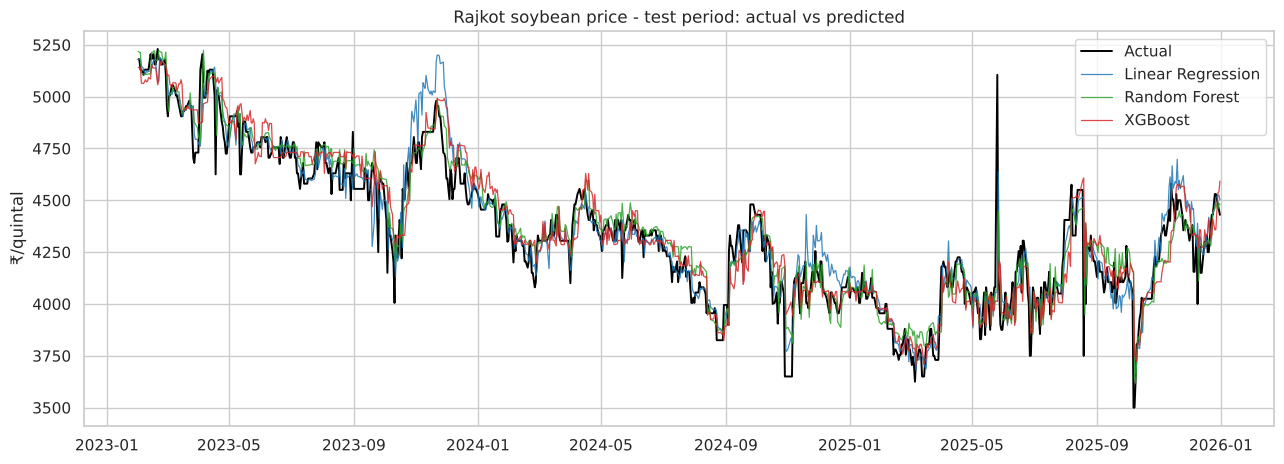

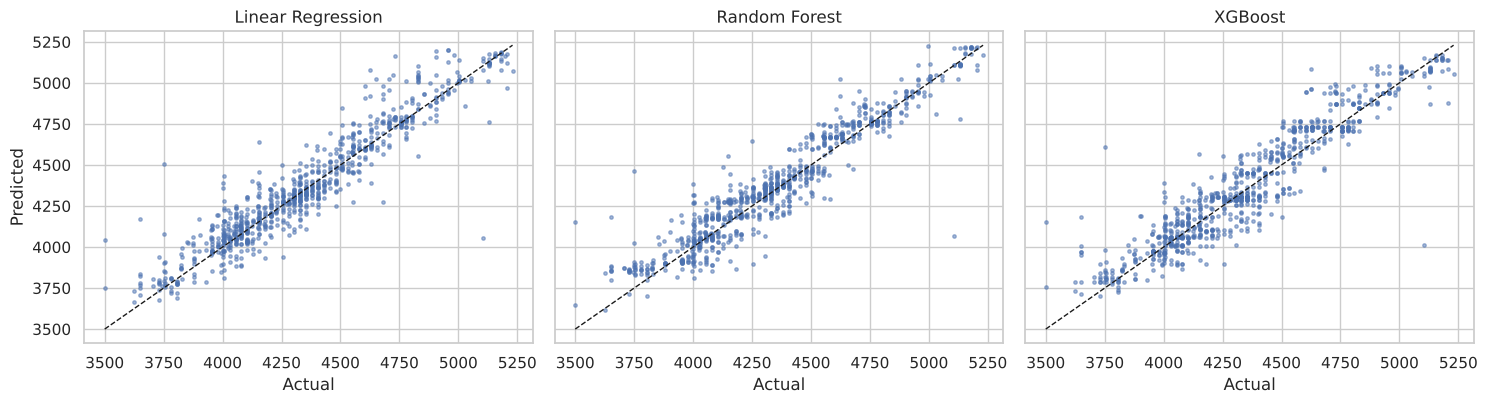

In [14]:
test_res = results[results['Set'] == 'Test'].set_index('Model').drop(columns='Set').sort_values('RMSE')
display(test_res.round(3))

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(preds.index, preds['Actual'], color='black', lw=1.4, label='Actual')
for name, c in zip(models, ['tab:blue', 'tab:green', 'tab:red']):
    ax.plot(preds.index, preds[name], lw=.9, alpha=.85, color=c, label=name)
ax.set_title('Rajkot soybean price - test period: actual vs predicted'); ax.set_ylabel('₹/quintal'); ax.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, name in zip(axes, models):
    ax.scatter(preds['Actual'], preds[name], s=6, alpha=.5)
    lo, hi = preds['Actual'].min(), preds['Actual'].max(); ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
    ax.set_title(name); ax.set_xlabel('Actual')
axes[0].set_ylabel('Predicted'); plt.tight_layout(); plt.show()

## 14. Feature Importance Analysis

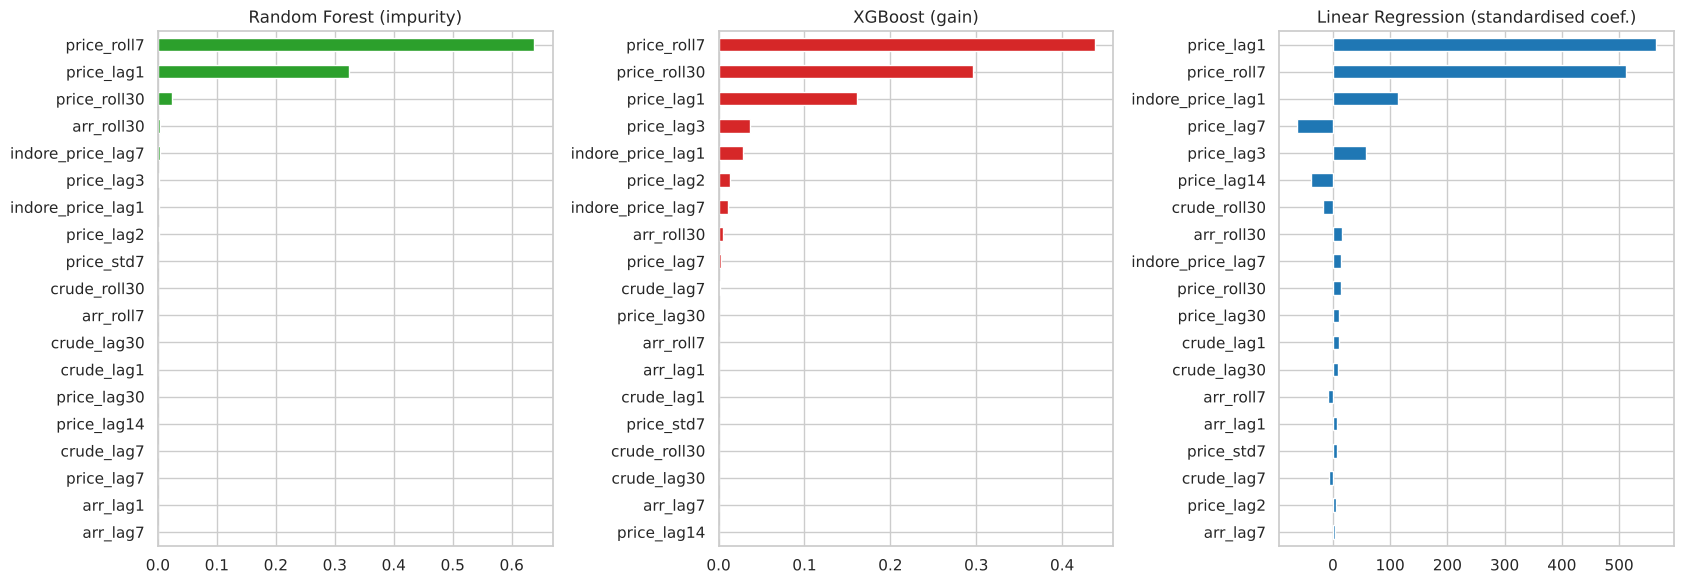

In [15]:
imp = pd.DataFrame({
    'Random Forest': models['Random Forest'].feature_importances_,
    'XGBoost':       models['XGBoost'].feature_importances_,
}, index=SELECTED)
lr_coef = pd.Series(models['Linear Regression'].coef_, index=SELECTED)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
imp['Random Forest'].sort_values().plot.barh(ax=axes[0], color='tab:green'); axes[0].set_title('Random Forest (impurity)')
imp['XGBoost'].sort_values().plot.barh(ax=axes[1], color='tab:red');        axes[1].set_title('XGBoost (gain)')
lr_coef.reindex(lr_coef.abs().sort_values().index).plot.barh(ax=axes[2], color='tab:blue'); axes[2].set_title('Linear Regression (standardised coef.)')
plt.tight_layout(); plt.show()

In [16]:
# Permutation importance of the best model on the TEST set (model-agnostic, more reliable than impurity importance)
best_name = test_res['RMSE'].drop('Naive (yesterday)', errors='ignore').idxmin()
pi = permutation_importance(models[best_name], inputs(best_name, 'test'), y_test, n_repeats=15,
                            random_state=RANDOM_STATE, scoring='neg_root_mean_squared_error', n_jobs=-1)
pi_s = pd.Series(pi.importances_mean, index=SELECTED).sort_values(ascending=False)
print(f'Permutation importance ({best_name}) - RMSE increase when feature is shuffled:')
print(pi_s.head(12).round(2).to_string())

# importance by variable group
def group(f):
    if f.startswith('price_'):          return 'Own price history'
    if f.startswith('arr_'):            return 'Own arrivals'
    if f.startswith('crude_'):          return 'Crude oil'
    if f.startswith(OTHER_MARKET + '_'): return 'Other-market price'
    return 'Calendar'
grp = pi_s.groupby(pi_s.index.map(group)).sum().sort_values(ascending=False)
print('\nBy variable group:'); print(grp.round(2).to_string())

Permutation importance (Random Forest) - RMSE increase when feature is shuffled:
price_roll7          165.71
price_lag1           119.01
price_roll30           5.91
indore_price_lag1      1.39
price_lag3             0.46
indore_price_lag7      0.30
price_lag7             0.15
arr_roll30             0.10
crude_lag30            0.08
price_std7             0.04
crude_roll30           0.02
crude_lag1             0.02

By variable group:
Own price history     289.87
Other-market price      1.69
Crude oil               0.05
Own arrivals           -0.01


## 15. Final Model Selection

In [17]:
final_name = best_name
final_model = models[final_name]
t = test_res.loc[final_name]
print(f'FINAL MODEL FOR RAJKOT: {final_name}')
print(f'  Test MAE  = {t.MAE:,.1f} ₹/q | RMSE = {t.RMSE:,.1f} ₹/q | R² = {t.R2:.4f}')
nv = test_res.loc['Naive (yesterday)']
print(f'  Naive "yesterday" baseline: MAE = {nv.MAE:,.1f} | RMSE = {nv.RMSE:,.1f} | R² = {nv.R2:.4f}')

joblib.dump({'model': final_model, 'model_name': final_name, 'features': SELECTED,
             'scaler': scaler if final_name == 'Linear Regression' else None}, 'rajkot_best_model.joblib')
preds.to_csv('rajkot_test_predictions.csv')
results.to_csv('rajkot_model_metrics.csv', index=False)
print('\nSaved: rajkot_best_model.joblib, rajkot_test_predictions.csv, rajkot_model_metrics.csv')

FINAL MODEL FOR RAJKOT: Random Forest
  Test MAE  = 81.1 ₹/q | RMSE = 115.4 ₹/q | R² = 0.8916
  Naive "yesterday" baseline: MAE = 57.2 | RMSE = 107.2 | R² = 0.9065

Saved: rajkot_best_model.joblib, rajkot_test_predictions.csv, rajkot_model_metrics.csv


**Notes**
- The best model is chosen on test RMSE, as requested. For a fully unbiased estimate, hold out a further period after choosing.
- Compare against the *Naive (yesterday)* row: daily mandi prices are very persistent, so a model must beat that baseline to add real value.
- Tree models cannot predict outside the price range seen in training; check the train/test price ranges printed in section 7.